# Préparation des données — tf_flowers (version corrigée)

**Changements par rapport à la version précédente**

| Problème dans l'ancienne version | Correction |
|---|---|
| Seulement 600 images / classe → ~1 800 images au total (daisy 633, roses 641, tulips 799 disponibles) | On garde **toutes** les images des 3 classes (≈ 2 070) : plus de données = moins d'overfitting |
| Split 60 / 20 / 20 → seulement 1 080 images d'entraînement | Split **70 / 15 / 15** stratifié |
| Resize sans anti-aliasing (images de 500×333 réduites brutalement) | `tf.image.resize(..., antialias=True)` |
| Images stockées en `float32` (×4 de mémoire, fichier .npz énorme) | Stockage en **`uint8`**, normalisation `/255` faite au moment de l'entraînement |
| Commentaires faux (« 32x32 », « 300 images ») et labels incohérents (`daisy/roses/tulips` vs `Daisy/Rose/Tulip`) | Une seule liste de noms de classes, cohérente partout |
| Déséquilibre de classes ignoré (tulips a ~25 % d'images en plus) | Les `class_weight` sont calculés dans le notebook d'entraînement |

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import tensorflow as tf
import tensorflow_datasets as tfds
from sklearn.model_selection import train_test_split

SEED = 42
IMG_SIZE = 128                          # 128x128 : assez de détails, bien moins de paramètres que 150x150
SELECTED = ['daisy', 'roses', 'tulips'] # classes retenues
CLASS_NAMES = ['Daisy', 'Rose', 'Tulip']

np.random.seed(SEED)
tf.random.set_seed(SEED)

I0000 00:00:1793925973.387034  110451 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1793925973.388269  110451 cudart_stub.cc:31] Could not find cuda drivers on your machine, GPU will not be used.
I0000 00:00:1793925973.465410  110451 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1793925975.418146  110451 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.

In [2]:
train_ds, info = tfds.load('tf_flowers', split='train', as_supervised=True, with_info=True)
all_class_names = info.features['label'].names
print(all_class_names)
print("Nombre total d'images :", info.splits['train'].num_examples)

['dandelion', 'daisy', 'tulips', 'sunflowers', 'roses']
Nombre total d'images : 3670


E0000 00:00:1793925990.496839  110451 cuda_platform.cc:57] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)
=== Source Location Trace: === 
external/xla/xla/stream_executor/cuda/cuda_status.cc:50



## 1. Exploration rapide

I0000 00:00:1793925997.748018  110580 tf_record_dataset_op.cc:398] The default buffer size is 262144, which is overridden by the user specified `buffer_size` of 8388608


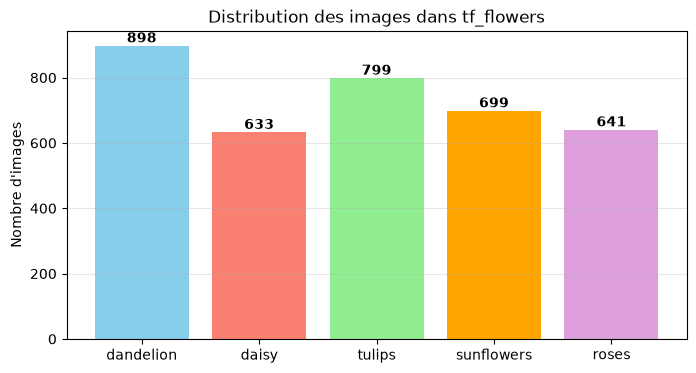

In [3]:
# Distribution des classes (dataset complet)
labels_all = np.array([int(l.numpy()) for _, l in train_ds])
unique, counts = np.unique(labels_all, return_counts=True)

plt.figure(figsize=(8, 4))
bars = plt.bar([all_class_names[i] for i in unique], counts,
               color=['skyblue', 'salmon', 'lightgreen', 'orange', 'plum'])
for b, c in zip(bars, counts):
    plt.text(b.get_x() + b.get_width()/2, c + 10, str(c), ha='center', fontweight='bold')
plt.title('Distribution des images dans tf_flowers')
plt.ylabel("Nombre d'images")
plt.grid(axis='y', alpha=0.3)
plt.show()

## 2. Filtrage des 3 classes + redimensionnement (toutes les images)

In [4]:
sel_ids = {name: all_class_names.index(name) for name in SELECTED}   # ex. {'daisy': 0, 'roses': 2, 'tulips': 4}
id_to_new = {orig: new for new, orig in enumerate(sel_ids.values())}  # -> 0, 1, 2

X_list, y_list = [], []
for image, label in train_ds:
    lab = int(label.numpy())
    if lab not in id_to_new:
        continue
    img = tf.image.resize(image, [IMG_SIZE, IMG_SIZE], antialias=True)
    img = tf.cast(tf.clip_by_value(tf.round(img), 0, 255), tf.uint8).numpy()
    X_list.append(img)
    y_list.append(id_to_new[lab])

X = np.stack(X_list)                 # uint8, (N, 128, 128, 3)
y = np.array(y_list, dtype=np.int64)
del X_list, y_list

print("X :", X.shape, X.dtype, "| valeurs :", X.min(), "->", X.max())
print("y :", y.shape, "| images par classe :", dict(zip(CLASS_NAMES, np.bincount(y))))

X : (2073, 128, 128, 3) uint8 | valeurs : 0 -> 255
y : (2073,) | images par classe : {'Daisy': np.int64(633), 'Rose': np.int64(641), 'Tulip': np.int64(799)}


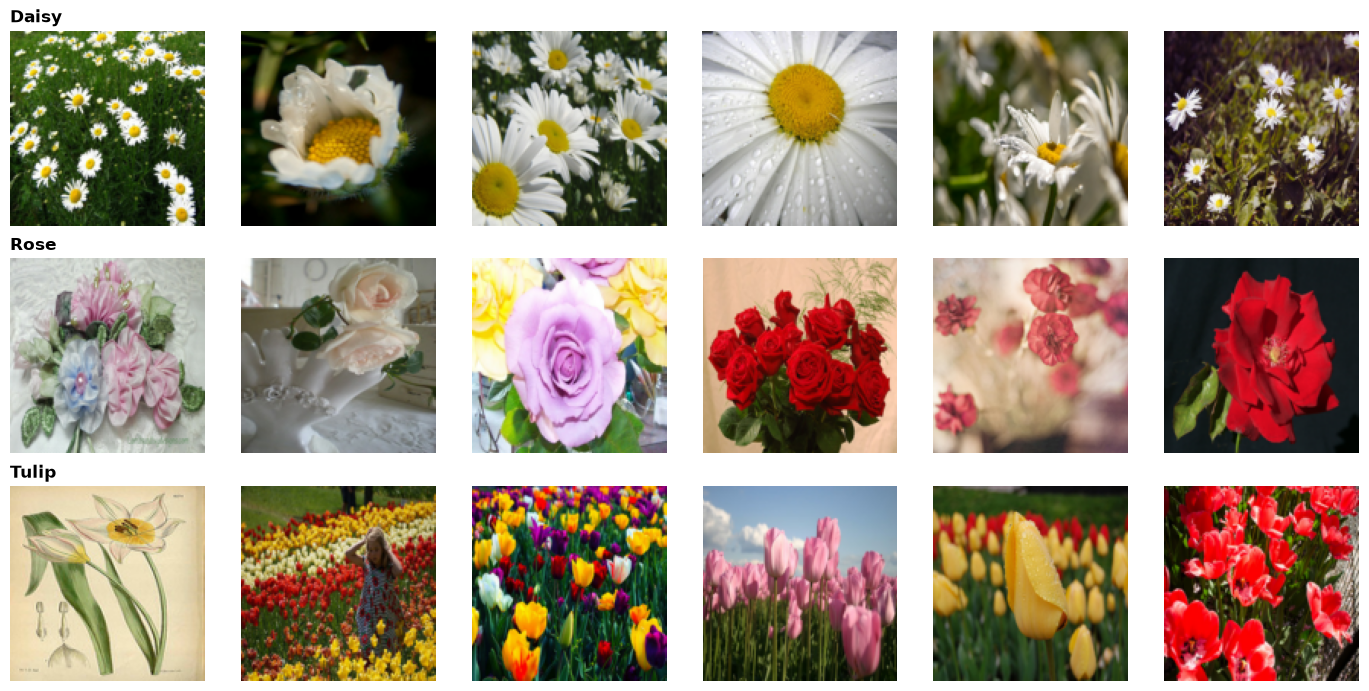

In [5]:
# Contrôle visuel : quelques images par classe
fig, axes = plt.subplots(3, 6, figsize=(14, 7))
rng = np.random.default_rng(SEED)
for c in range(3):
    idx = rng.choice(np.where(y == c)[0], 6, replace=False)
    for j, i in enumerate(idx):
        axes[c, j].imshow(X[i]); axes[c, j].axis('off')
    axes[c, 0].set_title(CLASS_NAMES[c], loc='left', fontweight='bold')
plt.tight_layout(); plt.show()

## 3. Split stratifié 70 / 15 / 15

,Train,Validation,Test,Total
Daisy,443,95,95,633
Rose,449,96,96,641
Tulip,559,120,120,799


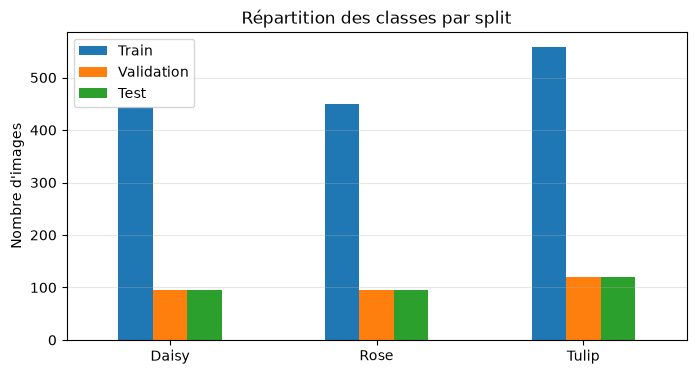

In [6]:
X_train, X_tmp, y_train, y_tmp = train_test_split(
    X, y, test_size=0.30, random_state=SEED, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(
    X_tmp, y_tmp, test_size=0.50, random_state=SEED, stratify=y_tmp)
del X_tmp, y_tmp

dist = pd.DataFrame({
    'Train': np.bincount(y_train, minlength=3),
    'Validation': np.bincount(y_val, minlength=3),
    'Test': np.bincount(y_test, minlength=3)}, index=CLASS_NAMES)
dist['Total'] = dist.sum(axis=1)
display(dist)

dist[['Train', 'Validation', 'Test']].plot(kind='bar', figsize=(8, 4))
plt.title('Répartition des classes par split'); plt.xticks(rotation=0)
plt.ylabel("Nombre d'images"); plt.grid(axis='y', alpha=0.3); plt.show()

In [7]:
# Vérification : aucune image identique entre train / val / test (pas de fuite de données)
def hashes(arr):
    return {hash(a.tobytes()) for a in arr}

h_tr, h_va, h_te = hashes(X_train), hashes(X_val), hashes(X_test)
print("Doublons train∩val  :", len(h_tr & h_va))
print("Doublons train∩test :", len(h_tr & h_te))
print("Doublons val∩test   :", len(h_va & h_te))

Doublons train∩val  : 0
Doublons train∩test : 1
Doublons val∩test   : 0


## 4. Sauvegarde (uint8, compressé)

In [8]:
np.savez_compressed(
    'tf_flowers_prepared.npz',
    X_train=X_train, y_train=y_train,
    X_val=X_val,     y_val=y_val,
    X_test=X_test,   y_test=y_test,
    class_names=np.array(CLASS_NAMES))

import os
print(f"Sauvegardé : tf_flowers_prepared.npz ({os.path.getsize('tf_flowers_prepared.npz')/1e6:.1f} Mo)")

Sauvegardé : tf_flowers_prepared.npz (85.5 Mo)
